Available columns: ['message_content', 'is_spam']
Columns after renaming: ['message', 'label']

First 5 messages:
                                             message label
0  Hello Lonnie,\n\nJust wanted to touch base reg...   ham
1  Congratulations, you've won a prize! Call us n...  spam
2  You have been pre-approved for a credit card w...  spam
3  Limited time offer, act now! Only a few spots ...  spam
4  Your loan has been approved! Transfer funds to...  spam

Class Distribution:
label
ham     500
spam    500
Name: count, dtype: int64

Model training completed!

Actual vs Predicted:
Actual Predicted
  spam      spam
   ham       ham
   ham       ham
   ham       ham
  spam      spam
  spam      spam
  spam      spam
  spam      spam
   ham       ham
   ham       ham

Model Evaluation:
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00       100
        spam

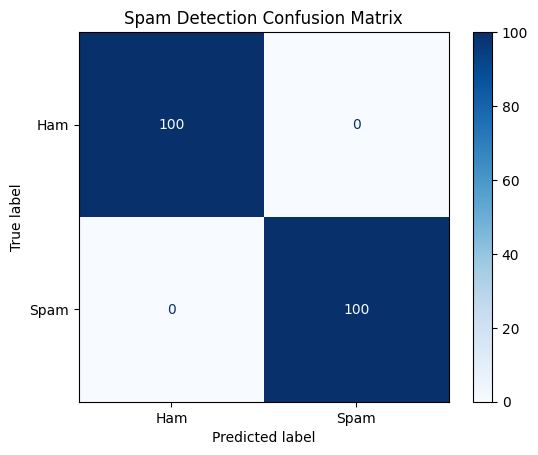


Enter a message to classify: 7
Predicted Class: HAM


In [10]:

import pandas as pd
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, accuracy_score
)

# 1. Load dataset
df = pd.read_csv("/content/spam_dataset.csv")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Available columns:", df.columns.tolist())

# CHANGE HERE: Enter the EXACT column name containing the text
TEXT_COLUMN = "message_content"

# CHANGE HERE: Enter the EXACT column name containing the target/label
TARGET_COLUMN = "is_spam"

# Rename columns to standard names used throughout this code
df = df.rename(columns={
    TEXT_COLUMN: "message",
    TARGET_COLUMN: "label"
})

# Check whether renaming worked
print("Columns after renaming:", df.columns.tolist())

# Select the required columns
df = df[["message", "label"]].dropna()

# 2. Convert target labels into standard class names
# CHANGE HERE if your dataset uses different target values
# Current assumption: 0 = ham, 1 = spam
df["label"] = df["label"].map({
    0: "ham",
    1: "spam"
})

df = df.dropna(subset=["label"])

print("\nFirst 5 messages:")
print(df.head())

print("\nClass Distribution:")
print(df["label"].value_counts())


# 3. Clean text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["message"] = df["message"].apply(clean_text)


# 4. Check duplicate messages
print("\nDuplicate messages:", df["message"].duplicated().sum())
print("Unique messages:", df["message"].nunique())


# 5. Separate features and target
X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 6. TF-IDF + Multinomial Naive Bayes
model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)

print("\nModel training completed!")


# 7. Predict test messages
y_pred = model.predict(X_test)

print("\nActual vs Predicted:")
print(pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": y_pred[:10]
}).to_string(index=False))


# 8. Evaluate the model
print("\nModel Evaluation:")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Precision:",
      round(precision_score(
          y_test, y_pred,
          pos_label="spam",
          zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test, y_pred,
          pos_label="spam",
          zero_division=0
      ), 4))

print("F1 Score:",
      round(f1_score(
          y_test, y_pred,
          pos_label="spam",
          zero_division=0
      ), 4))


# 9. Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["ham", "spam"],
    zero_division=0
))


# 10. Confusion matrix
labels = ["ham", "spam"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues")
plt.title("Spam Detection Confusion Matrix")
plt.show()


# 11. Predict a new message
new_message = input("\nEnter a message to classify: ")

prediction = model.predict([clean_text(new_message)])[0]

print("Predicted Class:", prediction.upper())
